In [1]:
pip install tensorflow roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.4/85.4 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 62.5 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.11.0.86
    Uninstalling opencv-python-headless-4.11.0.86:
      Successfully uninstalled opencv-python-headless-4.11.0.86
  Attempting uninstall: idna
    Found existing installation: idna 3.10
    Uninstalling idna-3.10:
      Successfully uninstalled idna-3.10


In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

In [3]:
from roboflow import Roboflow

import os
rf = Roboflow(api_key=os.environ["ROBOFLOW_API_KEY"])  # set your own key

project = rf.workspace("meva-wfywb").project("fish-fresh-and-non-fresh")

version = project.version(1)

dataset = version.download("folder")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to FISH-FRESH-AND-NON-FRESH-1 in folder:: 100%|██████████| 4303/4303 [00:00<00:00, 7621.13it/s]


In [4]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Image Augmentation for training with validation split
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2  # 20% of training data used for validation
)

# Validation data generator (only rescaling)
val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

# Test data generator (only rescaling)
test_datagen = ImageDataGenerator(rescale=1./255)

# Load and split training data
train_generator = train_datagen.flow_from_directory(
    '/content/FISH-FRESH-AND-NON-FRESH-1/train',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    subset='training'  # Training subset
)

val_generator = val_datagen.flow_from_directory(
    '/content/FISH-FRESH-AND-NON-FRESH-1/valid',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    subset='validation'  # Validation subset
)

# Load test data
test_generator = test_datagen.flow_from_directory(
    '/content/FISH-FRESH-AND-NON-FRESH-1/test',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False  # Important for consistent evaluation
)

print(f"Training samples: {train_generator.samples}")
print(f"Validation samples: {val_generator.samples}")
print(f"Test samples: {test_generator.samples}")


Found 2406 images belonging to 2 classes.
Found 171 images belonging to 2 classes.
Found 426 images belonging to 2 classes.
Training samples: 2406
Validation samples: 171
Test samples: 426


In [5]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

# Load the MobileNetV2 base model with pretrained ImageNet weights
base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Freeze the base model

# Add custom classification head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
predictions = Dense(1, activation='sigmoid')(x)

# Final model
model_4 = Model(inputs=base_model.input, outputs=predictions)

# Compile the model
model_4.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])

# Model summary
model_4.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [6]:
history = model_4.fit(
    train_generator,

    epochs=50,
    validation_data=test_generator
)

Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.


Epoch 1/50
76/76 ━━━━━━━━━━━━━━━━━━━━ 52s 533ms/step - accuracy: 0.6355 - loss: 0.6937 - val_accuracy: 0.8122 - val_loss: 0.4238
Epoch 2/50
76/76 ━━━━━━━━━━━━━━━━━━━━ 30s 396ms/step - accuracy: 0.7695 - loss: 0.4844 - val_accuracy: 0.8239 - val_loss: 0.3987
Epoch 3/50
76/76 ━━━━━━━━━━━━━━━━━━━━ 42s 410ms/step - accuracy: 0.8189 - loss: 0.4060 - val_accuracy: 0.8357 - val_loss: 0.3718
Epoch 4/50
76/76 ━━━━━━━━━━━━━━━━━━━━ 30s 400ms/step - accuracy: 0.8386 - loss: 0.3554 - val_accuracy: 0.8333 - val_loss: 0.3594
Epoch 5/50
76/76 ━━━━━━━━━━━━━━━━━━━━ 41s 405ms/step - accuracy: 0.8601 - loss: 0.3167 - val_accuracy: 0.8521 - val_loss: 0.3429
Epoch 6/50
76/76 ━━━━━━━━━━━━━━━━━━━━ 30s 398ms/step - accuracy: 0.8629 - loss: 0.3177 - val_accuracy: 0.8498 - val_loss: 0.3328
Epoch 7/50
76/76 ━━━━━━━━━━━━━━━━━━━━ 31s 404ms/step - accuracy: 0.8645 - loss: 0.3142 - val_accuracy: 0.8545 - val_loss: 0.3238
Epoch 8/50
76/76 ━━━━━━━━━━━━━━━━━━━━ 30s 397ms/step - accuracy: 0.8879 - loss: 0.2689 - val_accu

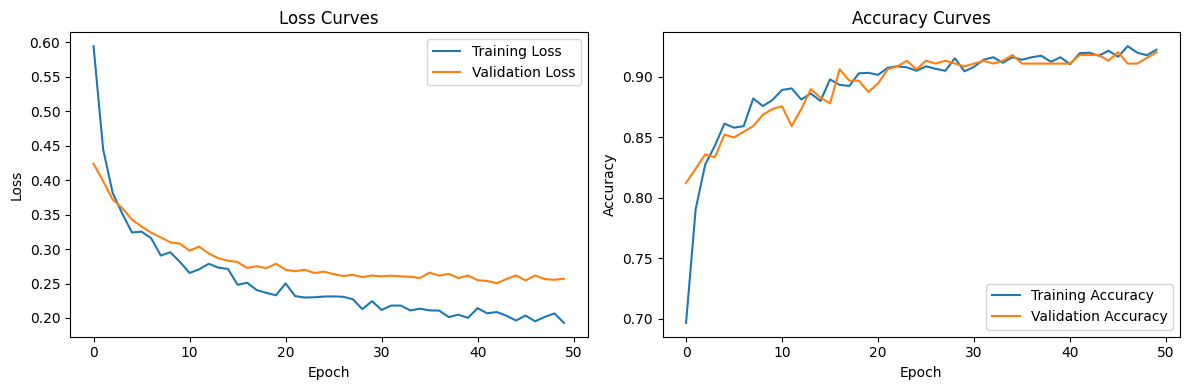

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 161ms/step - accuracy: 0.9184 - loss: 0.2799
Test Loss: 0.2570
Test Accuracy: 0.9202
14/14 ━━━━━━━━━━━━━━━━━━━━ 6s 279ms/step

Classification Report:
                precision    recall  f1-score   support

    Fresh Fish       0.92      0.93      0.92       220
Non Fresh Fish       0.93      0.91      0.92       206

      accuracy                           0.92       426
     macro avg       0.92      0.92      0.92       426
  weighted avg       0.92      0.92      0.92       426


Confusion Matrix:
[[205  15]
 [ 19 187]]


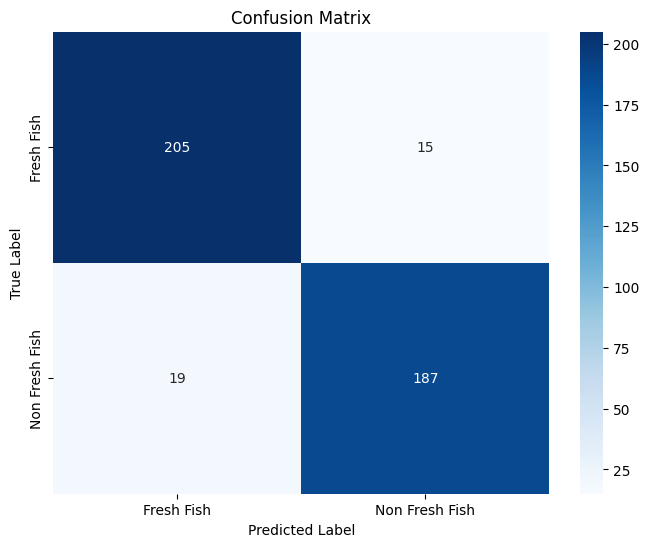

In [7]:

import matplotlib.pyplot as plt
# Plot training and validation loss
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Plot training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curves')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

# Evaluate the model on the test set
loss, accuracy = model_4.evaluate(test_generator)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

# Generate classification report
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder

# Get true labels and predicted probabilities
test_generator.reset() # Reset generator to ensure correct order
Y_true = test_generator.classes
Y_pred_prob = model_4.predict(test_generator)
Y_pred = (Y_pred_prob > 0.5).astype(int) # Convert probabilities to binary predictions

# Get class labels
class_labels = list(test_generator.class_indices.keys())

# Print classification report
print("\nClassification Report:")
print(classification_report(Y_true, Y_pred, target_names=class_labels))

# Print confusion matrix
print("\nConfusion Matrix:")
cm = confusion_matrix(Y_true, Y_pred)
print(cm)

# Optional: Visualize confusion matrix
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

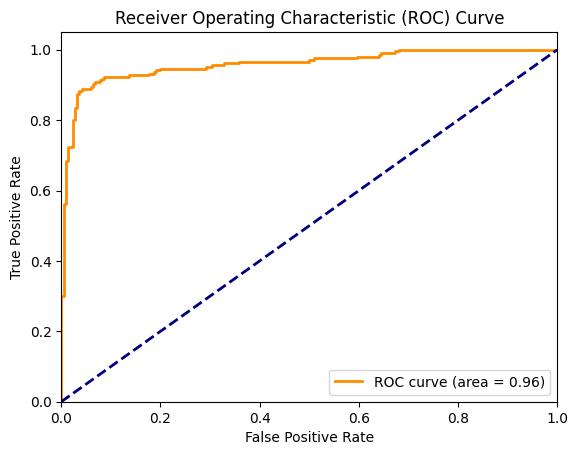


Optimal Threshold (maximizing TPR - FPR): 0.6126


In [9]:
# prompt: for above modle get roc curves and check optimal threshold

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# Get predicted probabilities for the positive class (class 1)
# Since it's binary classification with sigmoid, Y_pred_prob already contains probabilities for the positive class
Y_prob_positive = Y_pred_prob

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(Y_true, Y_prob_positive)

# Calculate AUC (Area Under the Curve)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

# Find optimal threshold (You can choose different criteria for "optimal")
# One common method is to find the threshold that maximizes the difference between TPR and FPR (Youden's J statistic)
optimal_threshold_index = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_threshold_index]
print(f"\nOptimal Threshold (maximizing TPR - FPR): {optimal_threshold:.4f}")

# You can also explore thresholds near the top-left corner of the ROC curve
# For example, finding a threshold that provides a good balance between TPR and FPR
# This might involve looking at the precision-recall trade-off as well, but for ROC,
# Youden's J is a simple and common approach.


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step

Optimal Threshold from Validation ROC (maximizing TPR - FPR): 0.0327

Test Accuracy with Optimal Threshold (0.0327): 0.4909

Classification Report with Optimal Threshold:
                precision    recall  f1-score   support

    Fresh Fish       0.95      0.41      0.57       220
Non Fresh Fish       0.61      0.98      0.75       206

      accuracy                           0.68       426
     macro avg       0.78      0.69      0.66       426
  weighted avg       0.78      0.68      0.66       426


Confusion Matrix with Optimal Threshold:
[[ 90 130]
 [  5 201]]


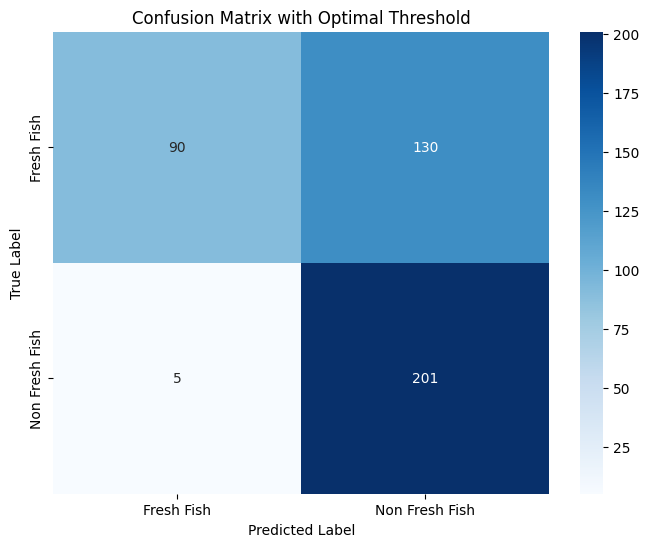

In [12]:
# prompt: val_generator with check optimal threshold and predict accuracy

import matplotlib.pyplot as plt
import numpy as np
# Get predicted probabilities on the validation set
val_generator.reset()
Y_true_val = val_generator.classes
Y_pred_prob_val = model_4.predict(val_generator)
Y_prob_positive_val = Y_pred_prob_val

# Calculate ROC curve for the validation set
fpr_val, tpr_val, thresholds_val = roc_curve(Y_true_val, Y_prob_positive_val)

# Find optimal threshold on the validation set (using Youden's J statistic)
optimal_threshold_index_val = np.argmax(tpr_val - fpr_val)
optimal_threshold_val = thresholds_val[optimal_threshold_index_val]
print(f"\nOptimal Threshold from Validation ROC (maximizing TPR - FPR): {optimal_threshold_val:.4f}")

# Predict on the test set using the optimal threshold found from the validation set
Y_pred_optimal = (Y_pred_prob > optimal_threshold_val).astype(int)

# Evaluate accuracy with the optimal threshold
accuracy_optimal = np.mean(Y_true == Y_pred_optimal)
print(f"\nTest Accuracy with Optimal Threshold ({optimal_threshold_val:.4f}): {accuracy_optimal:.4f}")

# Optional: Print classification report and confusion matrix with the optimal threshold
print("\nClassification Report with Optimal Threshold:")
print(classification_report(Y_true, Y_pred_optimal, target_names=class_labels))

print("\nConfusion Matrix with Optimal Threshold:")
cm_optimal = confusion_matrix(Y_true, Y_pred_optimal)
print(cm_optimal)

# Optional: Visualize confusion matrix with optimal threshold
plt.figure(figsize=(8, 6))
sns.heatmap(cm_optimal, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix with Optimal Threshold')
plt.show()